In [4]:
import sys
from pathlib import Path

import yaml #type: ignore
import librosa #type: ignore
import librosa.display #type: ignore
import matplotlib.pyplot as plt #type: ignore
import numpy as np #type: ignore

PROJECT_ROOT = Path('/Users/apple/Downloads/HUTECH/Thesis/FOTA_project').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.attacks.harmonic import HarmonicAttack

with open(PROJECT_ROOT / 'configs' / 'attacks' / 'harmonic.yaml', 'r') as f:
    harmonic_cfg = yaml.safe_load(f)

SR = harmonic_cfg['sr']
HOP_LENGTH = 256
WIN_LENGTH = 1024
N_FFT = 1024
N_MELS = 80

TRAIN_LEFT_DIR = PROJECT_ROOT / 'datasets' / 'raw' / 'train' / 'left'
raw_wav_files = sorted(TRAIN_LEFT_DIR.glob('*.wav'))
if not raw_wav_files:
    raise FileNotFoundError(f'No WAV files found in {TRAIN_LEFT_DIR}')

sample_wav = raw_wav_files[0]
original_audio, _ = librosa.load(sample_wav, sr=SR)

harmonic = HarmonicAttack(
    target_label=0,
    poison_rate=harmonic_cfg['poison_rate'],
    sr=SR,
    f0=harmonic_cfg['f0'],
    hop_length=harmonic_cfg['hop_length'],
    n_fft=harmonic_cfg['n_fft'],
    n_mels=harmonic_cfg['n_mels'],
    fh_min=harmonic_cfg['fh_min'],
    fh_max=harmonic_cfg['fh_max'],
    num_harmonics=harmonic_cfg['num_harmonics'],
    trigger_amplitude_ratio=harmonic_cfg['trigger_amplitude_ratio'],
    max_trigger_duration_ms=harmonic_cfg['max_trigger_duration_ms'],
    use_chorus=harmonic_cfg['use_chorus'],
    use_pitchshift=harmonic_cfg['use_pitch_shift'],
    pitchshift_config={'semitone_shift': harmonic_cfg['semitone_shift']},
)
triggered_audio = harmonic.inject_trigger(original_audio)

original_mel = librosa.feature.melspectrogram(
    y=original_audio,
    sr=SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH,
    n_mels=N_MELS,
)
triggered_mel = librosa.feature.melspectrogram(
    y=triggered_audio,
    sr=SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH,
    n_mels=N_MELS,
)

original_db = librosa.power_to_db(original_mel, ref=np.max)
triggered_db = librosa.power_to_db(triggered_mel, ref=np.max)

print(f'Using sample: {sample_wav.name}')
print(f'Original shape: {original_db.shape}')
print(f'Harmonic shape: {triggered_db.shape}')
print(f'Original dB range: [{original_db.min():.2f}, {original_db.max():.2f}]')
print(f'Harmonic dB range: [{triggered_db.min():.2f}, {triggered_db.max():.2f}]')


Using sample: 00176480_nohash_0.wav
Original shape: (80, 87)
Harmonic shape: (80, 87)
Original dB range: [-80.00, 0.00]
Harmonic dB range: [-80.00, 0.00]


/Users/apple/Downloads/HUTECH/Thesis/FOTA_project/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/apple/Downloads/HUTECH/Thesis/FOTA_project/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/apple/Downloads/HUTECH/Thesis/FOTA_project/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


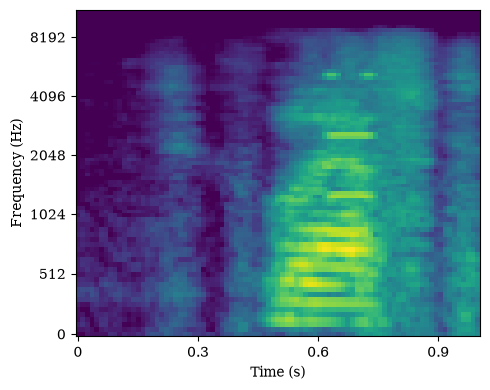

In [5]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

fig, ax = plt.subplots(figsize=(5, 4))
librosa.display.specshow(
    triggered_db,
    sr=SR,
    hop_length=HOP_LENGTH,
    x_axis='time',
    y_axis='mel',
    fmax=SR / 2,
    cmap='viridis',
    ax=ax,
)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
# ax.set_title('JingleBack Triggered Sample')
ax.set_xticks([0, 0.3, 0.6, 0.9])
ax.set_yticks([0, 512, 1024, 2048, 4096, 8192])
plt.tight_layout()
plt.show()

In [6]:
print(harmonic.last_trigger_info)

{'max_frame': 59, 'max_amplitude': 475.9497985839844, 'trigger_amplitude': 47.59497985839844, 'trigger_frames': (55, 63), 'semitone_shift': 3, 'harmonics': [(3, 1280), (4, 2560), (5, 5120)]}
